# Within-Method Surrogate Sensitivity: Does Surrogate Choice Matter, Within wCSET / Within CSET?

Reframes the original surrogate-comparison pilot's question. The original
`pilot_surrogate_power_analysis.ipynb` treated all 12 `(method, surrogate)`
combinations as one flat 12-level factor -- its main-effect test conflated
"methods differ" (large, expected) with "surrogates differ within a method"
(the thing actually of interest). This notebook splits by method and asks two
sharper questions per method, per outcome:

1. **Main effect (omnibus)**: averaged across regions, does surrogate choice
   change performance at all?
2. **Interaction**: does surrogate's effect *depend on which region* gets
   reconstructed -- e.g. two surrogates could be indistinguishable on average
   while diverging sharply in specific regions, a real and actionable effect
   the main-effect test alone would miss (exactly the pattern the original
   6-method pilot found: main effects saturated near 1.0, the interaction was
   the actual binding constraint).

**No new simulation or solving** -- reuses `pilot_surrogate_outcomes.tsv`
(208 runs x 12 conditions) unchanged, just split by method. Same model shape
as every other pilot here: `outcome ~ C(surrogate) + (1|region) +
(0+C(surrogate)|region) + (1|region:repetition)`, region as subject --
literally the original 6-method pilot's own model, refit twice (once per
method) with `surrogate` playing the role `method` used to play.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd

import mindmap as mm

METHODS = ["wcset", "cset"]
SURROGATES = ["true", "fused", "fused_bin", "geom_atlas", "geom_atlas_bin", "euclid"]
OUTCOMES = ["localization_error_hrp", "ap_hrp", "ap_pp", "correlation_auc"]
M = len(SURROGATES)

df = pd.read_csv("pilot_surrogate_outcomes.tsv", sep="\t")
df[["method", "surrogate"]] = df["condition"].str.split("_", n=1, expand=True)
print(f"{len(df)} rows, methods {sorted(df['method'].unique())}, surrogates {sorted(df['surrogate'].unique())}")
df.head()

2496 rows, methods ['cset', 'wcset'], surrogates ['euclid', 'fused', 'fused_bin', 'geom_atlas', 'geom_atlas_bin', 'true']


,run,condition,localization_error_hrp,ap_hrp,ap_pp,correlation_auc,region,repetition,method,surrogate
0,1,wcset_true,0.000000,0.540026,0.930348,0.299989,ctx-rh-posteriorcingulate_2,1,wcset,true
1,1,cset_true,3.057148,0.626221,0.908363,0.367253,ctx-rh-posteriorcingulate_2,1,cset,true
2,1,wcset_fused,2.224737,0.578679,0.933495,0.314196,ctx-rh-posteriorcingulate_2,1,wcset,fused
3,1,cset_fused,0.000000,0.684632,0.917503,0.354748,ctx-rh-posteriorcingulate_2,1,cset,fused
4,1,wcset_fused_bin,4.610860,0.605575,0.934502,0.318476,ctx-rh-posteriorcingulate_2,1,wcset,fused_bin


## Fit per method, per outcome

Same `fit_variance_components` call as every other pilot, just `fixed_col="surrogate"`
(6 levels) and the data pre-filtered to one method's 208 rows.

In [2]:
variance_components = {}   # {method: {outcome: {...}}}

for method in METHODS:
    df_method = df[df["method"] == method]
    variance_components[method] = {}
    for outcome in OUTCOMES:
        vc = mm.analysis.power.fit_variance_components(
            df_method, outcome,
            group_col="region", fixed_col="surrogate",
            vc_formula={"surrogate_region": "0 + C(surrogate)", "rep": "0 + C(repetition)"},
            fixed_levels=SURROGATES,
        )
        variance_components[method][outcome] = {
            "sigma2_region": vc["sigma2_region"],
            "sigma2_surrogate_region": vc["sigma2_surrogate_region"],
            "sigma2_rep": vc["sigma2_rep"],
            "sigma2_resid": vc["sigma2_resid"],
            "surrogate_means": vc["condition_means"],
        }

with open("pilot_surrogate_within_method_variance_components.json", "w") as f:
    json.dump(variance_components, f, indent=2)

pd.concat(
    {method: pd.DataFrame(variance_components[method]).T[
        ["sigma2_region", "sigma2_surrogate_region", "sigma2_rep", "sigma2_resid"]
    ] for method in METHODS},
    names=["method", "outcome"],
)

/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


sigma2_region sigma2_surrogate_region  \
method outcome                                                        
wcset  localization_error_hrp     22.696196               43.792102   
       ap_hrp                      0.016079                0.000443   
       ap_pp                       0.007681                0.000038   
       correlation_auc             0.001525                0.000144   
cset   localization_error_hrp    126.512741               22.067911   
       ap_hrp                      0.018495                0.000429   
       ap_pp                       0.010813                0.000164   
       correlation_auc             0.005468                0.000176   

                               sigma2_rep sigma2_resid  
method outcome                                          
wcset  localization_error_hrp  137.131492   184.709347  
       ap_hrp                    0.002797     0.000565  
       ap_pp                     0.000583     0.000094  
       correlation_auc           0.000302     0.000046  
cset   localization_error_hrp    0.845493   124.180877  
       ap_hrp                    0.000375     0.000263  
       ap_pp                     0.000156     0.000042  
       correlation_auc           0.000042     0.000028

## Power grid per method, per outcome

Unchanged `mindmap.core.power.simulate_splitplot_power`, `m=6` surrogates.

In [3]:
N_SIM = 2000
ALPHA = 0.05
k_grid = [10, 15, 20, 26, 35, 50, 75, 100]
r_grid = [3, 5, 8, 10, 15, 20]

power_results = {}       # {method: {outcome: {"condition": ..., "interaction": ...}}}
precision_results = {}   # {method: {outcome: ...}}

for mi, method in enumerate(METHODS):
    power_results[method] = {o: {"condition": np.zeros((len(k_grid), len(r_grid))),
                                  "interaction": np.zeros((len(k_grid), len(r_grid)))}
                              for o in OUTCOMES}
    precision_results[method] = {o: np.zeros(len(r_grid)) for o in OUTCOMES}

    for oi, outcome in enumerate(OUTCOMES):
        vc = variance_components[method][outcome]
        for i, k in enumerate(k_grid):
            for j, r in enumerate(r_grid):
                seed = mi * 10_000_000 + oi * 100_000 + i * 1000 + j
                pm, pw = mm.core.simulate_splitplot_power(
                    condition_means=vc["surrogate_means"],
                    sigma2_group=vc["sigma2_region"],
                    sigma2_interaction=vc["sigma2_surrogate_region"],
                    sigma2_rep=vc["sigma2_rep"],
                    sigma2_resid=vc["sigma2_resid"],
                    k=k, r=r, m=M, n_sim=N_SIM, alpha=ALPHA, seed=seed,
                )
                power_results[method][outcome]["condition"][i, j] = pm
                power_results[method][outcome]["interaction"][i, j] = pw
        for j, r in enumerate(r_grid):
            precision_results[method][outcome][j] = mm.core.precision_of_mean(
                vc["sigma2_rep"], vc["sigma2_resid"], r, M,
            )
    print(f"Power grid done for {method}")

np.savez(
    "pilot_surrogate_within_method_power_results.npz", k_grid=k_grid, r_grid=r_grid,
    **{f"{m}_{o}_condition": power_results[m][o]["condition"] for m in METHODS for o in OUTCOMES},
    **{f"{m}_{o}_interaction": power_results[m][o]["interaction"] for m in METHODS for o in OUTCOMES},
)

Power grid done for wcset


Power grid done for cset


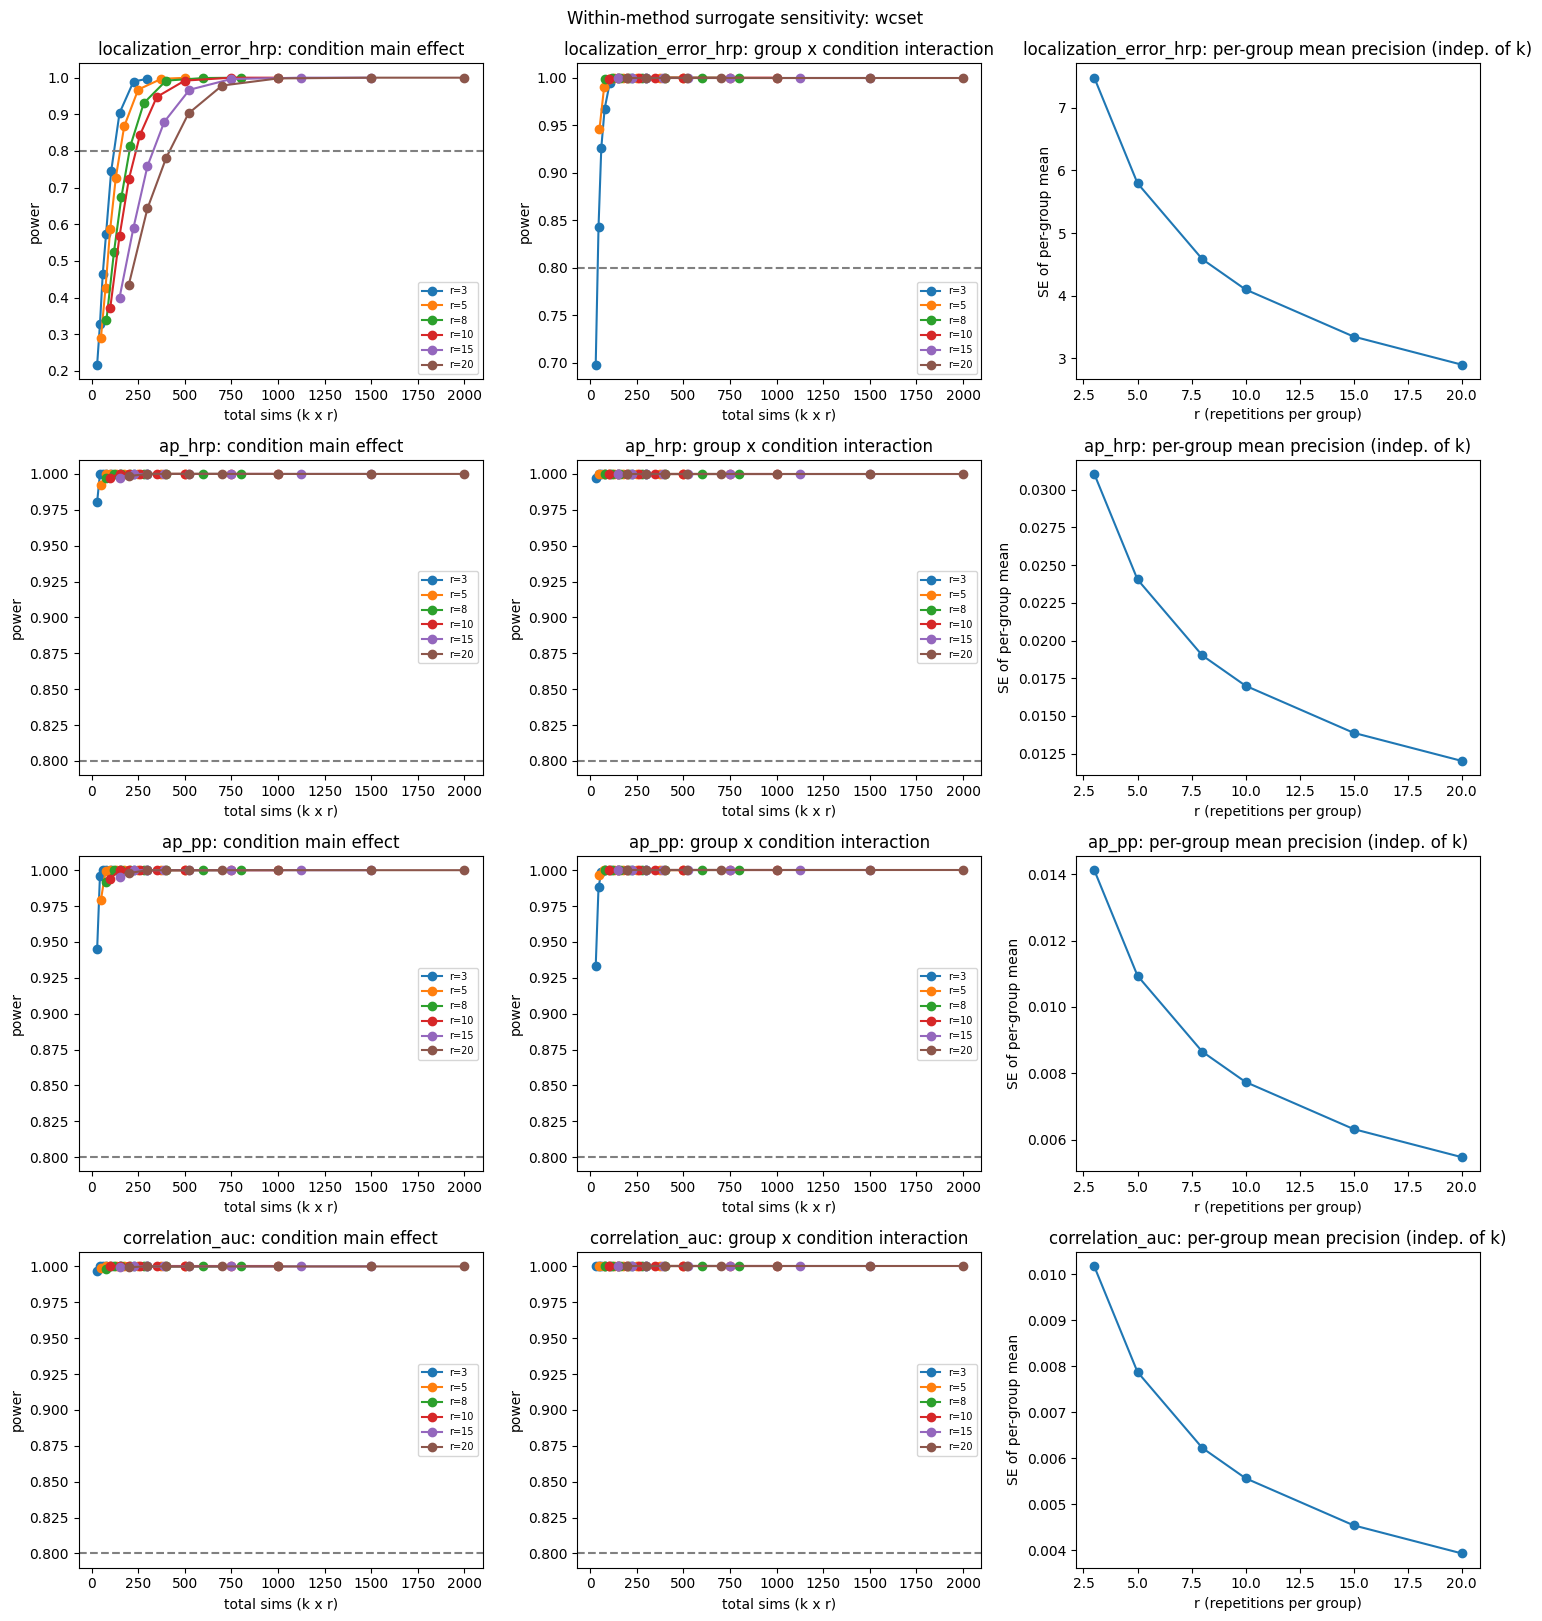

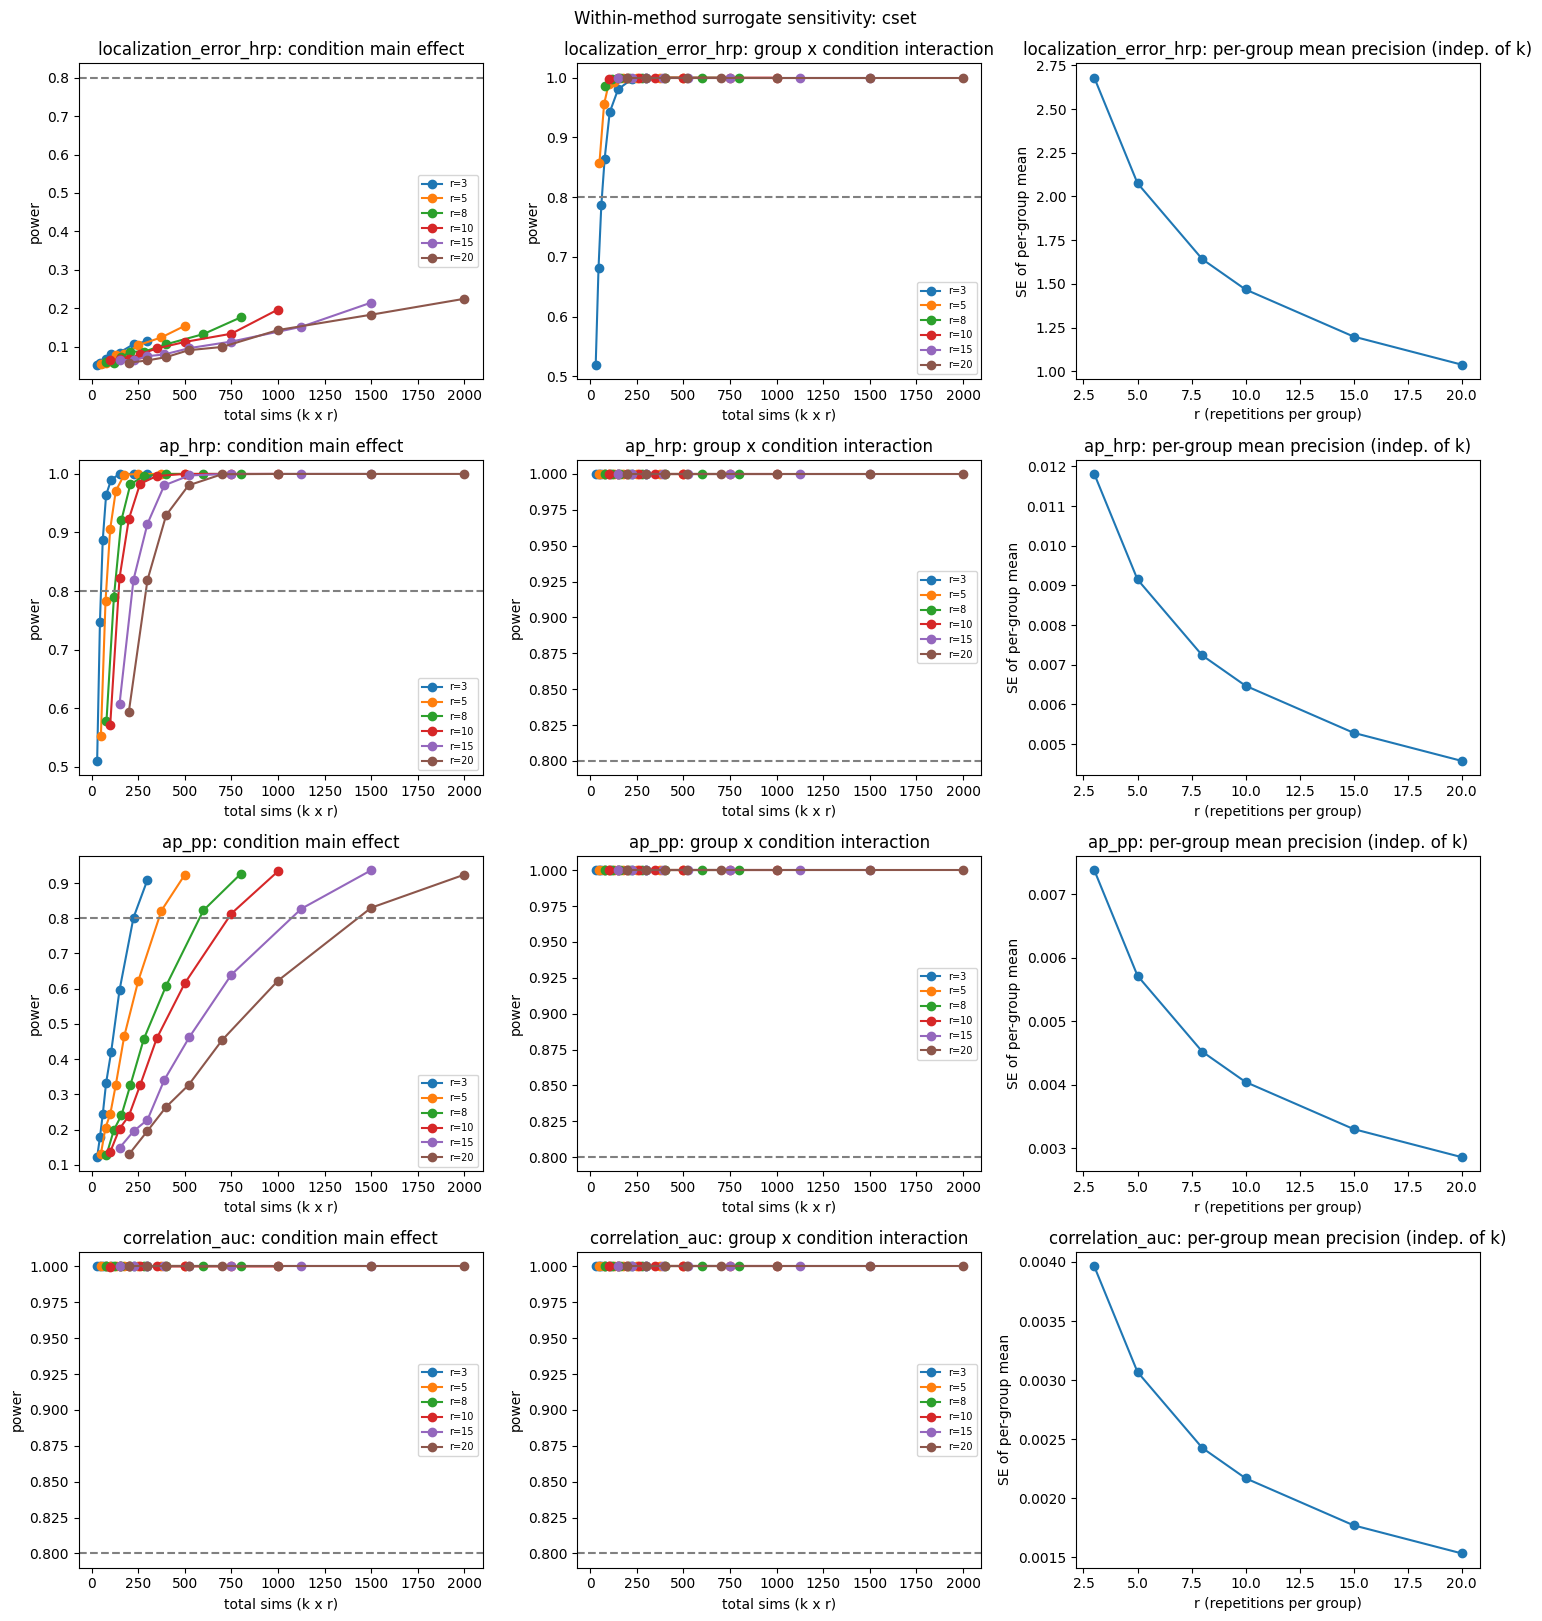

In [4]:
for method in METHODS:
    fig = mm.viz.plot_power_precision_curves(power_results[method], precision_results[method], k_grid, r_grid, OUTCOMES)
    fig.suptitle(f"Within-method surrogate sensitivity: {method}", y=1.01)
    fig.savefig(f"pilot_surrogate_within_method_power_curves_{method}.png", dpi=130)

## Recommendation, per method

Sized to the worst outcome, separately for each method (they may need
different designs -- no reason to assume wCSET and CSET are equally
surrogate-sensitive).

In [5]:
def worst_case_power(power_results_method, test):
    worst = np.ones((len(k_grid), len(r_grid)))
    for outcome in OUTCOMES:
        worst = np.minimum(worst, power_results_method[outcome][test])
    return worst

THRESHOLD = 0.8
for method in METHODS:
    print(f"=== {method} ===")
    for name, test in [("surrogate main effect", "condition"), ("surrogate x region interaction", "interaction")]:
        worst = worst_case_power(power_results[method], test)
        ok = worst >= THRESHOLD
        if not ok.any():
            print(f"  {name}: no (k, r) in this grid reaches {THRESHOLD} power across every outcome -- extend the grid "
                  f"(best achieved: {worst.max():.3f}).")
            continue
        total_sims = np.array(k_grid)[:, None] * np.array(r_grid)[None, :]
        candidates = np.where(ok, total_sims, np.inf)
        i, j = np.unravel_index(np.argmin(candidates), candidates.shape)
        print(f"  {name}: smallest design clearing {THRESHOLD} power everywhere -- "
              f"k={k_grid[i]} regions, r={r_grid[j]} repetitions "
              f"(worst-case power={worst[i, j]:.3f}, total sims/surrogate={k_grid[i]*r_grid[j]}).")

=== wcset ===
  surrogate main effect: smallest design clearing 0.8 power everywhere -- k=50 regions, r=3 repetitions (worst-case power=0.903, total sims/surrogate=150).
  surrogate x region interaction: smallest design clearing 0.8 power everywhere -- k=15 regions, r=3 repetitions (worst-case power=0.843, total sims/surrogate=45).
=== cset ===
  surrogate main effect: no (k, r) in this grid reaches 0.8 power across every outcome -- extend the grid (best achieved: 0.225).
  surrogate x region interaction: smallest design clearing 0.8 power everywhere -- k=10 regions, r=5 repetitions (worst-case power=0.858, total sims/surrogate=50).
